In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [2]:
df = pd.read_csv("calorie_dataset.csv")
df.head()

,protein_g,carbs_g,fat_g,fiber_g,sugar_g,calories,calorie_class
0,22.5,65.2,13.7,9.9,26.7,479.0,medium
1,15.9,20.7,16.8,7.6,15.0,316.0,low
2,28.3,62.4,14.5,10.8,15.3,524.0,medium
3,23.3,18.6,7.9,17.0,0.2,250.0,low
4,30.8,55.1,31.9,12.5,7.2,602.0,medium


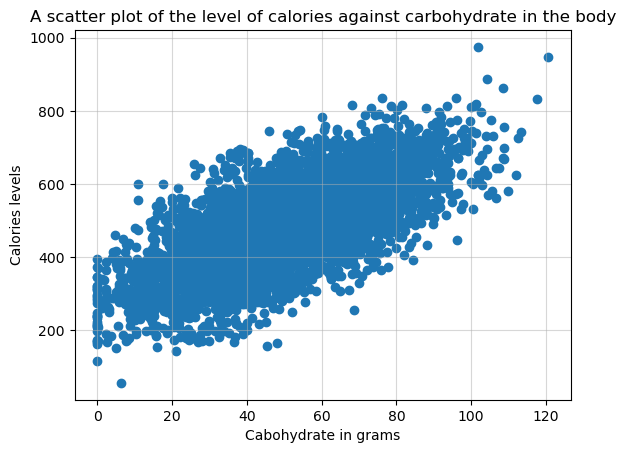

In [3]:
plt.scatter(x= df["carbs_g"], y=df["calories"]),
plt.xlabel("Cabohydrate in grams"),
plt.ylabel("Calories levels"),
plt.title('A scatter plot of the level of calories against carbohydrate in the body'),
plt.grid(True, alpha=0.5)
plt.show();

In [4]:
X = df[["carbs_g", "protein_g","fat_g"]]
y = df["calories"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size=0.2, random_state=42)

In [6]:
model= LinearRegression()

In [7]:
model.fit(X_train,y_train)


LinearRegression()

In [8]:
predictions = model.predict(X_test)

In [9]:
mse = mean_squared_error(y_test,predictions)
r2 = r2_score(y_test,predictions)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error (MSE): 880.20
R² Score: 0.93


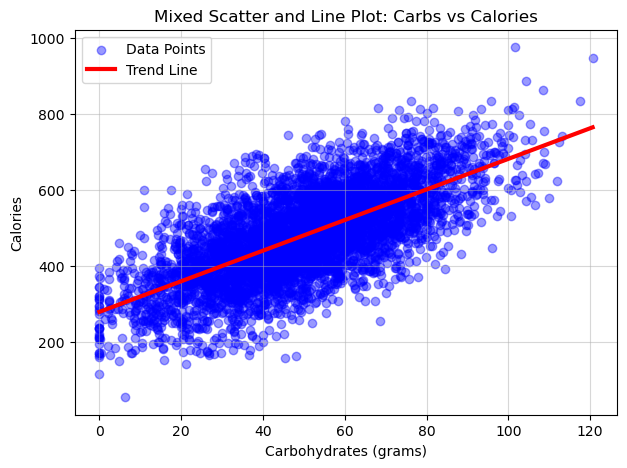

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(x=df["carbs_g"], y=df["calories"], color="blue", alpha=0.4, label="Data Points")

m, c = np.polyfit(df["carbs_g"], df["calories"], 1)
x_line = np.linspace(df["carbs_g"].min(), df["carbs_g"].max(), 100)
y_line = m * x_line + c

plt.plot(x_line, y_line, color="red", linewidth=3, label="Trend Line")

plt.xlabel("Carbohydrates (grams)")
plt.ylabel("Calories")
plt.title("Mixed Scatter and Line Plot: Carbs vs Calories")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

In [11]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Multiplier (Coefficient)': model.coef_
})

print("Model Intercept (Baseline Calories):", f"{model.intercept_:.2f}")
print("\nMacronutrient Multipliers:")
print(coefficients.to_string(index=False))

Model Intercept (Baseline Calories): 0.44

Macronutrient Multipliers:
  Feature  Multiplier (Coefficient)
  carbs_g                  4.045544
protein_g                  3.935954
    fat_g                  8.925077


In [12]:
def predict_my_meal(protein, carbs, fat): 
    custom_data = [[carbs, protein, fat]]
    custom_columns = ["carbs_g", "protein_g", "fat_g"]
    
    custom_meal = pd.DataFrame(custom_data, columns=custom_columns)
    predicted_calories = model.predict(custom_meal)[0]
    
    print(f"Carbs: {carbs}g | Protein:{protein}g | Fat: {fat}g")
    print(f"Predicted Total Calories: {predicted_calories:.1f} kcal")

predict_my_meal(protein=10, carbs=40, fat=5)

Carbs: 40g | Protein:10g | Fat: 5g
Predicted Total Calories: 246.3 kcal
